In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('food_wastage_dataset.csv')
df.head()

,Country,Year,Food Category,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Population (Million),Household Waste (%)
0,Australia,2019,Fruits & Vegetables,19268.63,18686.68,72.69,87.59,53.64
1,Indonesia,2019,Prepared Food,3916.97,4394.48,192.52,1153.99,30.61
2,Germany,2022,Dairy Products,9700.16,8909.16,166.94,1006.11,48.08
3,France,2023,Fruits & Vegetables,46299.69,40551.22,120.19,953.05,31.91
4,France,2023,Beverages,33096.57,36980.82,104.74,1105.47,36.06


In [6]:
df.shape

(5000, 8)

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

Country                      0
Year                         0
Food Category                0
Total Waste (Tons)           0
Economic Loss (Million $)    0
Avg Waste per Capita (Kg)    0
Population (Million)         0
Household Waste (%)          0
dtype: int64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Country                    5000 non-null   str    
 1   Year                       5000 non-null   int64  
 2   Food Category              5000 non-null   str    
 3   Total Waste (Tons)         5000 non-null   float64
 4   Economic Loss (Million $)  5000 non-null   float64
 5   Avg Waste per Capita (Kg)  5000 non-null   float64
 6   Population (Million)       5000 non-null   float64
 7   Household Waste (%)        5000 non-null   float64
dtypes: float64(5), int64(1), str(2)
memory usage: 312.6 KB


In [10]:
df.dtypes

Country                          str
Year                           int64
Food Category                    str
Total Waste (Tons)           float64
Economic Loss (Million $)    float64
Avg Waste per Capita (Kg)    float64
Population (Million)         float64
Household Waste (%)          float64
dtype: object

In [11]:
df.describe()

,Year,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Population (Million),Household Waste (%)
count,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2021.015600,25061.780072,25039.703870,109.46397,706.606416,50.060890
std,1.999239,14245.119588,14620.236429,51.93373,402.546464,11.596203
min,2018.000000,502.610000,406.690000,20.09000,11.290000,30.020000
25%,2019.000000,12783.737500,12612.477500,64.05000,350.602500,40.012500
50%,2021.000000,24865.220000,24428.155000,110.08000,713.530000,50.295000
75%,2023.000000,37471.035000,37146.037500,154.52500,1057.255000,60.125000
max,2024.000000,49990.760000,59228.930000,199.97000,1399.970000,70.000000


In [12]:
cm = df.corr(numeric_only = True)
cm

,Year,Total Waste (Tons),Economic Loss (Million $),Avg Waste per Capita (Kg),Population (Million),Household Waste (%)
Year,1.000000,0.003452,0.002113,0.013716,0.008015,-0.013416
Total Waste (Tons),0.003452,1.000000,0.974522,0.019987,0.024048,0.010367
Economic Loss (Million $),0.002113,0.974522,1.000000,0.017097,0.022253,0.006167
Avg Waste per Capita (Kg),0.013716,0.019987,0.017097,1.000000,-0.029190,-0.019394
Population (Million),0.008015,0.024048,0.022253,-0.029190,1.000000,-0.004848
Household Waste (%),-0.013416,0.010367,0.006167,-0.019394,-0.004848,1.000000


In [13]:
df['Country'].unique()

<StringArray>
[   'Australia',    'Indonesia',      'Germany',       'France',
        'India',        'China',           'UK', 'South Africa',
        'Japan',          'USA',       'Brazil', 'Saudi Arabia',
        'Italy',        'Spain',       'Mexico',    'Argentina',
       'Canada',  'South Korea',       'Russia',       'Turkey']
Length: 20, dtype: str

In [14]:
df['Food Category'].unique()

<StringArray>
['Fruits & Vegetables',       'Prepared Food',      'Dairy Products',
           'Beverages',      'Meat & Seafood',    'Grains & Cereals',
         'Frozen Food',        'Bakery Items']
Length: 8, dtype: str

In [15]:
category_waste = (df.groupby("Food Category")["Total Waste (Tons)"].sum().sort_values(ascending=False))
category_waste

Food Category
Prepared Food          17929317.92
Beverages              16354455.29
Bakery Items           15587955.51
Fruits & Vegetables    15522081.20
Meat & Seafood         15371347.52
Dairy Products         15292167.33
Frozen Food            15045115.02
Grains & Cereals       14206460.57
Name: Total Waste (Tons), dtype: float64

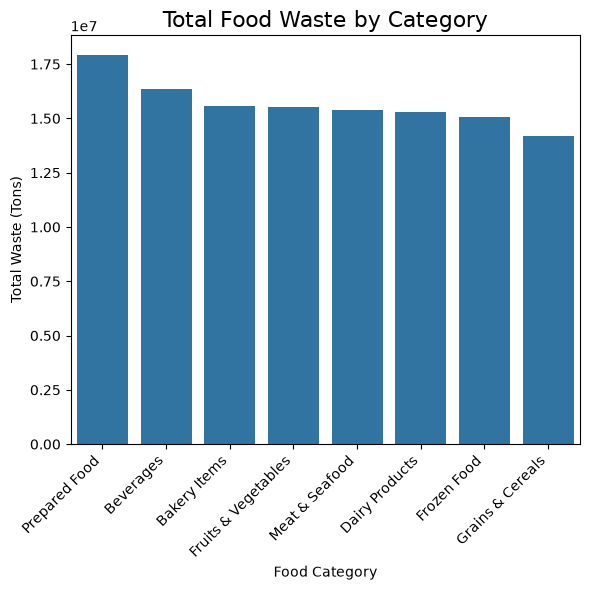

In [17]:
plt.figure(figsize=(6, 6))
sns.barplot(x=category_waste.index,y=category_waste.values)
plt.title("Total Food Waste by Category", fontsize=16)
plt.xlabel("Food Category")
plt.ylabel("Total Waste (Tons)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [18]:
highest_waste_category = category_waste.idxmax()
highest_waste_amount = category_waste.max()
print("Highest-waste category:", highest_waste_category)
print("Total waste (tons):", round(highest_waste_amount, 2))

Highest-waste category: Prepared Food
Total waste (tons): 17929317.92


In [19]:
country_waste = (df.groupby("Country")["Total Waste (Tons)"].sum().sort_values(ascending=False))
country_waste.head(10)

Country
Turkey       6879885.81
Canada       6790678.49
Spain        6790574.25
Germany      6760053.01
Mexico       6589169.52
USA          6446334.63
China        6411096.18
Brazil       6391752.50
France       6334495.00
Indonesia    6294447.74
Name: Total Waste (Tons), dtype: float64

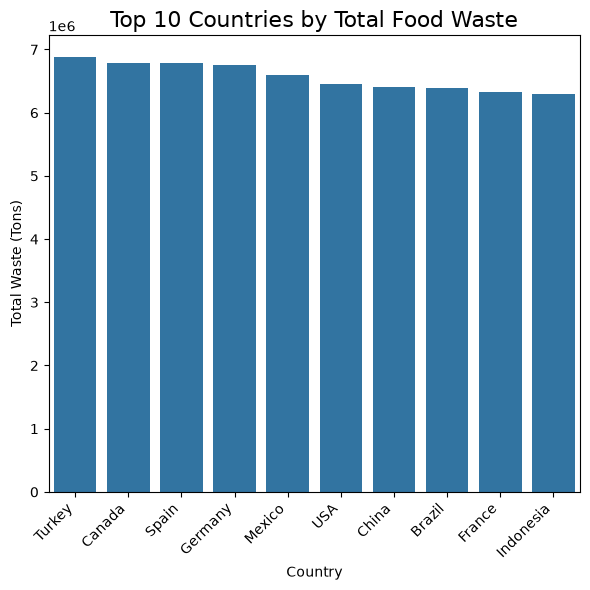

In [21]:
top_10_countries = country_waste.head(10)
plt.figure(figsize=(6, 6))
sns.barplot(x=top_10_countries.index,y=top_10_countries.values)
plt.title("Top 10 Countries by Total Food Waste", fontsize=16)
plt.xlabel("Country")
plt.ylabel("Total Waste (Tons)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [22]:
print("Highest-waste country:", country_waste.idxmax())
print("Total waste (tons):", round(country_waste.max(), 2))
print("\nLowest-waste country:", country_waste.idxmin())
print("Total waste (tons):", round(country_waste.min(), 2))

Highest-waste country: Turkey
Total waste (tons): 6879885.81

Lowest-waste country: South Korea
Total waste (tons): 5609107.07


In [24]:
yearly_waste = (df.groupby("Year")["Total Waste (Tons)"].sum().sort_index())
yearly_waste

Year
2018    17625290.55
2019    17527936.61
2020    18128400.36
2021    18305242.89
2022    17107497.90
2023    18444672.83
2024    18169859.22
Name: Total Waste (Tons), dtype: float64

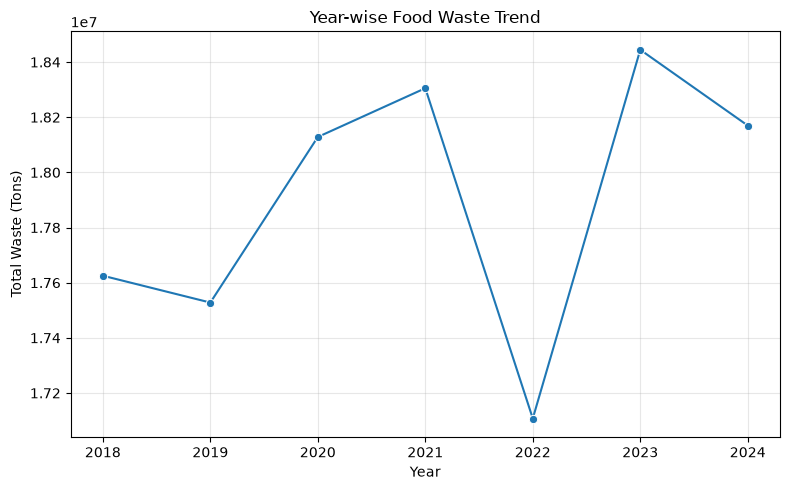

In [26]:
plt.figure(figsize=(8, 5))
sns.lineplot(x=yearly_waste.index,y=yearly_waste.values,marker="o")
plt.title("Year-wise Food Waste Trend")
plt.xlabel("Year")
plt.ylabel("Total Waste (Tons)")
plt.xticks(yearly_waste.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()